# Monte Carlo study of the rank-based IV AFT estimator (aaivaft), version 2

This notebook produces every number, table, and figure of the Monte Carlo section of the Stata Journal paper. It replaces `aaivaft_montecarlo.ipynb`, whose stored results did not match the tables in the paper.

The data generating process follows the design of Acharya, Khalaf, Menon, Voia, Yazbeck, and Wensley (2026). The estimator follows `aaivaft` version 2.26:

1. The rank statistic projects the scores on the instrument residualized on the covariates.
2. The critical value is the floor(M(1 - alpha))th smallest simulated value, as in the command.
3. The three closed-form scores are logistic, Gumbel, and exponential.
4. The rank-only benchmark projects the scores on the residualized treatment.

Running all cells writes `mc_results_v2.json`, two LaTeX tables, and two figures next to the notebook. Code comments are in Spanish and figure labels in English.

In [1]:
import os, json, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

OUT = os.getcwd()

# estilo de figuras: letra 9, leyenda debajo, rotulos en ingles
plt.rcParams.update({"font.size":9,"axes.titlesize":9,"axes.labelsize":9,
                     "legend.fontsize":9,"xtick.labelsize":9,"ytick.labelsize":9,
                     "font.family":"serif"})

## Scores

The three scores are applied to the fractional ranks $u = r/(n+1)$.

In [2]:
def score_logistic(u):    return np.log(u/(1.0-u))
def score_gumbel(u):      return -np.log(-np.log(u))
def score_exponential(u): return -np.log(1.0-u)
SCORES = {"logistic": score_logistic, "gumbel": score_gumbel,
          "exponential": score_exponential}

def col_ranks(A):
    # rangos 1..n por columna (los datos son continuos o llevan jitter)
    return A.argsort(axis=0).argsort(axis=0) + 1

## Data generating process

$$y_{ig} = \beta s_{ig} + X_{ig}'\delta + \nu_{ig} + \eta_{ig}, \qquad
s_{ig} = \pi z_{ig} + \sqrt{1-\rho^2}\,u_{ig} + \rho(\eta_{ig}+\nu_{ig}).$$

There are four hospitals of unequal size. The baseline $\eta$ is extreme value with a hospital specific scale, the frailty $\nu$ is log Gamma, $u$ is normal, and $z$ is a binary instrument. The covariates are hospital dummies, a count of chronic conditions, and a cardiac indicator. With `censor > 0`, the largest durations are censored and treated as observed, because the command does not adjust for censoring.

In [3]:
def make_data(n, pi, rho, beta, rng, censor=0.0):
    g = 4
    shares = np.array([0.40, 0.30, 0.20, 0.10])
    sizes  = np.floor(shares*n).astype(int)
    sizes[-1] = n - sizes[:-1].sum()
    hosp = np.repeat(np.arange(g), sizes)
    mu    = np.array([2.0, 2.5, 3.0, 3.5])   # localizacion por hospital
    sigma = np.array([0.8, 1.0, 1.2, 1.5])   # escala por hospital

    # duracion base: valor extremo con escala por hospital, media cero
    p = rng.uniform(1e-6, 1-1e-6, n)
    eta = -sigma[hosp]*np.log(-np.log(p))
    eta = eta - eta.mean()

    # fragilidad log Gamma
    nu = np.log(rng.gamma(2.0, 1.0, n)); nu = nu - nu.mean()

    u = rng.standard_normal(n)
    z = (rng.uniform(0, 1, n) < 0.30).astype(float)
    chronic = rng.poisson(0.6, n).astype(float)
    cardiac = (rng.uniform(0, 1, n) < 0.18).astype(float)

    # tratamiento endogeno
    s = pi*z + np.sqrt(1-rho**2)*u + rho*(eta+nu)

    D = np.zeros((n, g-1))
    for j in range(1, g):
        D[:, j-1] = (hosp == j).astype(float)
    X = np.column_stack([np.ones(n), D, chronic, cardiac])
    delta = np.array([2.0, mu[1]-mu[0], mu[2]-mu[0], mu[3]-mu[0], 0.15, 0.25])
    y = beta*s + X@delta + nu + eta

    if censor > 0:   # censura por la derecha, tratada como observada
        t = np.exp(y - y.mean())
        clim = np.quantile(t, 1-censor)
        y = np.where(t <= clim, y, np.log(clim) + y.mean())
    return y, s, X, z

## Estimator

For each grid value $\beta_0$, the residuals $M_X(y - s\beta_0)$ are ranked and scored, and $G(\beta_0) = (\tilde z'c)^2/(\tilde z'\tilde z)$ with $\tilde z = M_X z$. The critical value comes from random permutations of the ranks. The same permutations are used for the three scores within a replication.

In [4]:
ALPHA = 0.05

def annihilator(X):
    XtX_inv = np.linalg.inv(X.T@X)
    return lambda v: v - X@(XtX_inv@(X.T@v))

def g_curve(My, Ms, proj, grid, fn, jitter):
    # G(beta0) en la grilla, proyectando sobre proj (ya residualizado)
    E = My[:, None] - np.outer(Ms, grid) + jitter[:, None]
    C = fn(col_ranks(E)/(E.shape[0]+1.0))
    return (proj@C)**2/(proj@proj)

def g_critical(proj, R, fn):
    # valor critico: el floor(M(1-alpha))-esimo menor valor simulado, como en aaivaft
    n, M = R.shape
    C = fn(R/(n+1.0))
    G = np.sort((proj@C)**2/(proj@proj))
    return G[int(np.floor(M*(1-ALPHA))) - 1]

def rank_set(grid, G, gc):
    keep = G < gc
    if not keep.any():
        return np.nan, np.nan, "empty"
    lo, hi = grid[keep].min(), grid[keep].max()
    return lo, hi, ("edge" if (keep[0] or keep[-1]) else "bounded")

## One Monte Carlo cell

A cell returns, for each score, the size of the test at the true $\beta$, the bias and RMSE of the rank IV HLS estimate, the bias of the rank-only benchmark, the share of bounded confidence sets, and, if asked, the rejection curve over the grid.

In [5]:
def mc_cell(n, pi, rho, beta, R, Msim, grid, seed, censor=0.0, want_curve=False):
    rng = np.random.default_rng(seed)
    jitter = np.arange(n)*1e-10
    itrue = int(np.argmin(np.abs(grid-beta)))
    acc = {sc: {"rej":0, "hls":[], "noiv":[], "bounded":0, "len":[],
                "curve":np.zeros(len(grid))} for sc in SCORES}
    for r in range(R):
        y, s, X, z = make_data(n, pi, rho, beta, rng, censor=censor)
        M1 = annihilator(X)
        My, Ms, zt = M1(y), M1(s), M1(z)
        Rsim = col_ranks(rng.uniform(0, 1, (n, Msim)))   # permutaciones comunes
        for sc, fn in SCORES.items():
            gc = g_critical(zt, Rsim, fn)
            G  = g_curve(My, Ms, zt, grid, fn, jitter)
            a = acc[sc]
            a["hls"].append(grid[int(np.argmin(G))])
            a["rej"] += int(G[itrue] >= gc)
            lo, hi, kind = rank_set(grid, G, gc)
            if kind == "bounded":
                a["bounded"] += 1; a["len"].append(hi-lo)
            Gno = g_curve(My, Ms, Ms, grid, fn, jitter)   # benchmark sin IV
            a["noiv"].append(grid[int(np.argmin(Gno))])
            if want_curve:
                a["curve"] += (G >= gc)
    out = {}
    for sc, a in acc.items():
        h, hn = np.array(a["hls"]), np.array(a["noiv"])
        out[sc] = dict(size=a["rej"]/R,
                       hls_bias=float(h.mean()-beta),
                       hls_rmse=float(np.sqrt(((h-beta)**2).mean())),
                       noiv_bias=float(hn.mean()-beta),
                       bounded_frac=a["bounded"]/R,
                       median_len=float(np.median(a["len"])) if a["len"] else float("nan"))
        if want_curve:
            out[sc]["curve"] = (a["curve"]/R).tolist()
    return out

## Experiment

The true coefficient is $\beta = 0.3$. Each cell uses 500 replications and 500 permutations for the critical value, at the nominal 5% level.

In [6]:
t0 = time.time()
BETA = 0.3
grid = np.round(np.arange(-0.5, 1.5+1e-9, 0.02), 2)
R, Msim = 500, 500
res = {"beta":BETA, "grid":grid.tolist(), "R":R, "Msim":Msim, "cells":{}}

design = [(200,pi,rho) for rho in (0.75, 0.0) for pi in (0.2, 0.4, 0.8, 1.2)]
sizes  = [(n,0.4,0.75) for n in (100, 500, 1000)]
seed = 100
for (n,pi,rho) in design + sizes:
    seed += 1
    key = f"n{n}_pi{pi}_rho{rho}"
    res["cells"][key] = mc_cell(n, pi, rho, BETA, R, Msim, grid, seed,
                                want_curve=(n == 200 and rho == 0.75 and pi in (0.4, 0.8)))
    c = res["cells"][key]
    print(key, "  size:", [round(c[s]["size"],3) for s in SCORES])

res["cells"]["n200_pi0.4_rho0.75_cens0.15"] = mc_cell(200, 0.4, 0.75, BETA, R, Msim, grid,
                                                      seed=777, censor=0.15)
with open(os.path.join(OUT, "mc_results_v2.json"), "w") as f:
    json.dump(res, f, indent=1)
print("elapsed minutes:", round((time.time()-t0)/60, 1))

n200_pi0.2_rho0.75   size: [0.05, 0.056, 0.058]


n200_pi0.4_rho0.75   size: [0.042, 0.036, 0.048]


n200_pi0.8_rho0.75   size: [0.062, 0.058, 0.052]


n200_pi1.2_rho0.75   size: [0.07, 0.068, 0.06]


n200_pi0.2_rho0.0   size: [0.056, 0.066, 0.06]


...

n200_pi1.2_rho0.0   size: [0.034, 0.032, 0.036]


n100_pi0.4_rho0.75   size: [0.058, 0.056, 0.056]


n500_pi0.4_rho0.75   size: [0.056, 0.06, 0.05]


n1000_pi0.4_rho0.75   size: [0.036, 0.04, 0.044]


elapsed minutes: 1.4


## LaTeX tables

The two tables are written as `tab_sim_design.tex` and `tab_sim_n.tex`, ready for `\input{}` in the paper.

In [7]:
cells = res["cells"]; S = list(SCORES)
f3 = lambda x: f"{x:.3f}"
fb = lambda x: f"{x:+.3f}"

rows = []
for (n,pi,rho) in [(200,0.2,0.75),(200,0.4,0.75),(200,0.8,0.75),(200,1.2,0.75),
                   (200,0.4,0.0),(200,0.8,0.0)]:
    c = cells[f"n{n}_pi{pi}_rho{rho}"]
    rows.append(f"{n} & {pi} & {rho:.2f} & " + " & ".join(f3(c[s]["size"]) for s in S)
                + " & " + " & ".join(fb(c[s]["hls_bias"]) for s in S) + r" \\")
cc = cells["n200_pi0.4_rho0.75_cens0.15"]
rows.append(r"\addlinespace" + "\n" + r"\multicolumn{3}{l}{15\% censoring} & "
            + " & ".join(f3(cc[s]["size"]) for s in S) + " & "
            + " & ".join(fb(cc[s]["hls_bias"]) for s in S) + r" \\")
tab1 = "\n".join([r"\begin{tabular}{ccc ccc ccc}", r"\toprule",
 r" & & & \multicolumn{3}{c}{Size} & \multicolumn{3}{c}{IV bias} \\",
 r"\cmidrule(lr){4-6}\cmidrule(lr){7-9}",
 r"$n$ & $\pi$ & $\rho$ & Log. & Gum. & Exp. & Log. & Gum. & Exp. \\", r"\midrule"]
 + rows + [r"\bottomrule", r"\end{tabular}"])
open(os.path.join(OUT, "tab_sim_design.tex"), "w").write(tab1 + "\n")

rows = []
for n in (100, 200, 500, 1000):
    c = cells[f"n{n}_pi0.4_rho0.75"]
    rows.append(f"{n} & " + " & ".join(f3(c[s]["size"]) for s in S) + " & "
                + " & ".join(f3(c[s]["hls_rmse"]) for s in S) + r" \\")
tab2 = "\n".join([r"\begin{tabular}{c ccc ccc}", r"\toprule",
 r" & \multicolumn{3}{c}{Size} & \multicolumn{3}{c}{IV RMSE} \\",
 r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}",
 r"$n$ & Log. & Gum. & Exp. & Log. & Gum. & Exp. \\", r"\midrule"]
 + rows + [r"\bottomrule", r"\end{tabular}"])
open(os.path.join(OUT, "tab_sim_n.tex"), "w").write(tab2 + "\n")
print(tab1); print(); print(tab2)

\begin{tabular}{ccc ccc ccc}
\toprule
 & & & \multicolumn{3}{c}{Size} & \multicolumn{3}{c}{IV bias} \\
\cmidrule(lr){4-6}\cmidrule(lr){7-9}
$n$ & $\pi$ & $\rho$ & Log. & Gum. & Exp. & Log. & Gum. & Exp. \\
\midrule
200 & 0.2 & 0.75 & 0.050 & 0.056 & 0.058 & +0.053 & +0.080 & +0.097 \\
200 & 0.4 & 0.75 & 0.042 & 0.036 & 0.048 & -0.070 & -0.083 & -0.091 \\
200 & 0.8 & 0.75 & 0.062 & 0.058 & 0.052 & -0.043 & -0.044 & -0.048 \\
200 & 1.2 & 0.75 & 0.070 & 0.068 & 0.060 & -0.010 & -0.010 & -0.011 \\
200 & 0.4 & 0.00 & 0.048 & 0.044 & 0.048 & +0.062 & +0.066 & +0.075 \\
200 & 0.8 & 0.00 & 0.030 & 0.036 & 0.034 & -0.000 & -0.001 & -0.003 \\
\addlinespace
\multicolumn{3}{l}{15\% censoring} & 0.064 & 0.060 & 0.058 & -0.124 & -0.138 & -0.149 \\
\bottomrule
\end{tabular}

\begin{tabular}{c ccc ccc}
\toprule
 & \multicolumn{3}{c}{Size} & \multicolumn{3}{c}{IV RMSE} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}
$n$ & Log. & Gum. & Exp. & Log. & Gum. & Exp. \\
\midrule
100 & 0.058 & 0.056 & 0.056 & 0.576 &

## Numbers quoted in the text

In [8]:
for pi in (0.2, 0.4, 0.8, 1.2):
    c = cells[f"n200_pi{pi}_rho0.75"]["logistic"]
    print(f"pi={pi}: bounded sets {100*c['bounded_frac']:.0f}%,  no-IV bias {c['noiv_bias']:+.3f}")
for pi in (0.4, 0.8):
    c = cells[f"n200_pi{pi}_rho0.0"]["logistic"]
    print(f"pi={pi}, rho=0: no-IV bias {c['noiv_bias']:+.3f}")
allsize = [cells[k][s]["size"] for k in cells for s in S]
print("size range over all cells and scores:", min(allsize), max(allsize))

pi=0.2: bounded sets 5%,  no-IV bias +1.001
pi=0.4: bounded sets 12%,  no-IV bias +0.982
pi=0.8: bounded sets 42%,  no-IV bias +0.934
pi=1.2: bounded sets 75%,  no-IV bias +0.862
pi=0.4, rho=0: no-IV bias -0.003
pi=0.8, rho=0: no-IV bias -0.004
size range over all cells and scores: 0.03 0.07


## Figures

Figure 1 shows the rejection curve of the logistic score for the weak and the medium instrument. Figure 2 compares the bias of the rank IV estimate with the bias of the rank-only benchmark. Legends go below the plot.

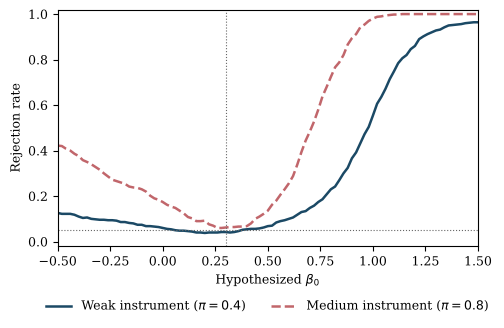

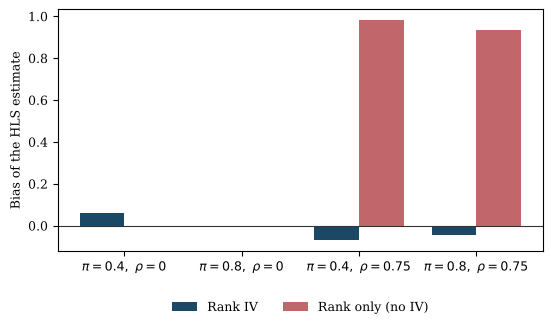

In [9]:
c_w = cells["n200_pi0.4_rho0.75"]["logistic"]["curve"]
c_m = cells["n200_pi0.8_rho0.75"]["logistic"]["curve"]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.plot(grid, c_w, color="#1b4965", lw=1.8, label="Weak instrument ($\\pi=0.4$)")
ax.plot(grid, c_m, color="#c1666b", lw=1.8, ls="--", label="Medium instrument ($\\pi=0.8$)")
ax.axhline(0.05, color="#666666", lw=0.8, ls=":"); ax.axvline(BETA, color="#666666", lw=0.8, ls=":")
ax.set_xlabel("Hypothesized $\\beta_0$"); ax.set_ylabel("Rejection rate")
ax.set_ylim(-0.02, 1.02); ax.set_xlim(grid.min(), grid.max())
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "fig1_rejection.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUT, "fig1_rejection.png"), dpi=200, bbox_inches="tight")
plt.show()

cases = [("n200_pi0.4_rho0.0", "$\\pi=0.4,\\ \\rho=0$"),
         ("n200_pi0.8_rho0.0", "$\\pi=0.8,\\ \\rho=0$"),
         ("n200_pi0.4_rho0.75", "$\\pi=0.4,\\ \\rho=0.75$"),
         ("n200_pi0.8_rho0.75", "$\\pi=0.8,\\ \\rho=0.75$")]
ivb = [cells[k]["logistic"]["hls_bias"] for k, _ in cases]
nob = [cells[k]["logistic"]["noiv_bias"] for k, _ in cases]
x = np.arange(len(cases)); w = 0.38
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.bar(x-w/2, ivb, w, color="#1b4965", label="Rank IV")
ax.bar(x+w/2, nob, w, color="#c1666b", label="Rank only (no IV)")
ax.axhline(0, color="#333333", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([l for _, l in cases])
ax.set_ylabel("Bias of the HLS estimate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "fig3_bias.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUT, "fig3_bias.png"), dpi=200, bbox_inches="tight")
plt.show()